# Residual model generation pipeline

In [ ]:
import os
import torch
import shutil
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes

from LMCE.networks import MLP
from LMCE.utils import min_max
from LMCE.trainers import train
from LMCE.residual_calculation import indi_residuals
from LMCE.data_prep import prepare_data, create_dataloader
from LMCE.model_to_c_conversion import exportNet, nn_c_model_test

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times']

## Preparing the data
First define where the data is stored, then it can be loaded, the `prepare_data` function calculates the labels (residual forces).

In [2]:
# Get train data paths
USE_PAYLOAD = True
training_data_paths = [f"./data/payload/train_clean/{i:02}.npy" for i in range(25)]
testing_data_paths = [f"./data/payload/test_clean/00.npy"]

residual_func = lambda data: indi_residuals(data, make_smooth=True, verbose=0, spline_segments=200)
kappas = np.array([
    2.0938753372837369e-10,
    2.2766702598220073e-10,
    1.906494181367591e-10,
    2.4578364131636854e-10
])
kappas = np.array([])

X_train, y_train_ = prepare_data(training_data_paths,
                                 save_as="train_data_payload",
                                 residual_func=residual_func,
                                 overwrite=False,
                                 payload=USE_PAYLOAD,
                                 kappas=kappas,
                                 verbose=1)

X_test, y_test_ = prepare_data(testing_data_paths,
                               save_as="test_data_payload",
                               shuffle_data=False,
                               residual_func=residual_func,
                               overwrite=False,
                               payload=USE_PAYLOAD,
                               kappas=kappas,
                               verbose=1)

print("X_train.shape: ", X_train.shape)
print("y_train_.shape: ", y_train_.shape)
print("X_test.shape: ", X_test.shape)
print("y_test_.shape: ", y_test_.shape)

Data already exists, loading from files...
Data already exists, loading from files...
X_train.shape:  (58538, 28)
y_train_.shape:  (58538, 6)
X_test.shape:  (1115, 28)
y_test_.shape:  (1115, 6)


In [3]:
_, X_mins, X_maxs = min_max(X_train.copy())
X_mins[:6] = -1.
X_maxs[:6] = 1.
X_train, _, _ = min_max(X_train, X_mins, X_maxs)
X_test, _, _ = min_max(X_test, X_mins, X_maxs)

y_train, y_mins, y_maxs = min_max(y_train_)
y_test, _, _ = min_max(y_test_, y_mins, y_maxs)

train_loader = create_dataloader(X_train, y_train)
val_loader = create_dataloader(X_test, y_test)

print("Train size: ", X_train.shape[0])
print("Test size: ", X_test.shape[0])
print("X dim: ", X_train.shape[1], "y dim: ", y_train.shape[1])

Train size:  58538
Test size:  1115
X dim:  28 y dim:  6


We can plot the flight path and residual forces like this

In [4]:
# THREE_D = True

# data_path = testing_data_paths[0]
# visual_scale = 1.

# if THREE_D:
#     fig = plt.figure()
#     ax = plt.axes(projection='3d')

# data = np.load(data_path, allow_pickle=True).item()
# label = os.path.basename(data_path)

# x = data["pos"][:, 0]
# y = data["pos"][:, 1]
# z = data["pos"][:, 2]
# origin = data["pos"]

# f, _ = residual_func(data)
# vector = np.array([f[:, 0], f[:, 1], f[:, 2]]).T * visual_scale
# if THREE_D:
#     ax.quiver(origin[:, 0], origin[:, 1], origin[:, 2], vector[:, 0], vector[:, 1],
#               vector[:, 2], color='r', alpha=.1, label=f"Residual forces (scaled by {visual_scale})")
# else:
#     plt.quiver(origin[:, 0], origin[:, 1], vector[:, 0], vector[:, 1], color='r',
#               alpha=.1, label=f"Residual forces (scaled by {visual_scale})")

# if THREE_D:
#     ax.plot3D(x, y, z, label=label)
# else:
#     plt.plot(x, y, label=label)

# # Calculate the avg. residual force for each axis
# for j, v in enumerate(["x", "y", "z"]):
#     f_j = [f_[j] for f_ in f]
#     print(f"{label} mean residual f_{v}: {sum(f_j)/len(f_j)}")

# plt.title("Residual forces on quadrotor trajectory")
# plt.legend()
# plt.axis("equal")
# plt.show()

## Training the model

100%|██████████| 128/128 [00:26<00:00,  4.81epoch/s, train_loss=0.00268, val_loss=0.00426]


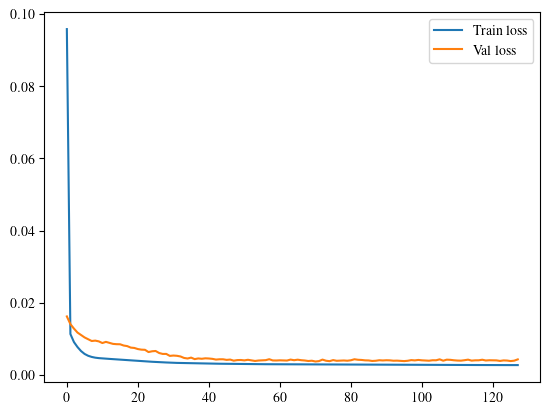

Done!


In [22]:
# Create and train neural network
model = MLP(input_size=X_train.shape[1], output_size=y_train.shape[1], hidden_layers=[8, 8])
model = train(model, train_loader, val_loader, lr=3e-4, scheduler_gamma=.92, scheduler_step_size=10, device="cpu", epochs=128, verbose=1)
model.save("mlp")
model.load("mlp")

## Testing the model

100%|██████████| 1/1 [00:00<00:00, 20.39files/s]


(1115, 6)
Average force error: (x, y, z) N -> (0.0300, 0.0274, 0.0208) N
Average torque error: (x, y, z) N -> (0.0957, 0.1173, 0.0880) N


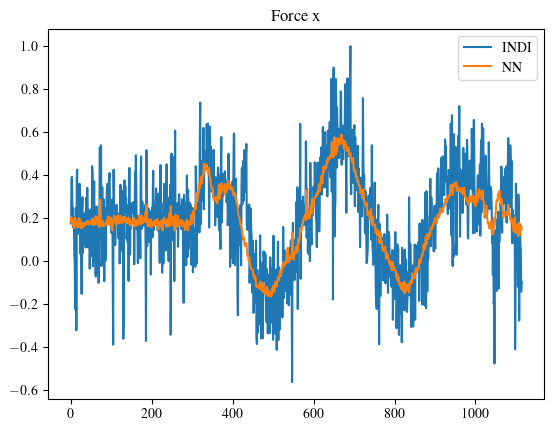

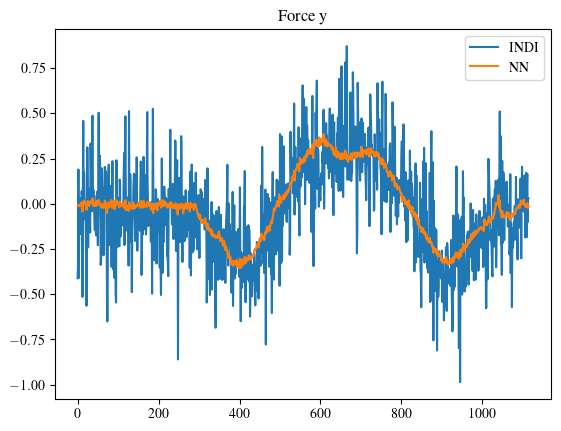

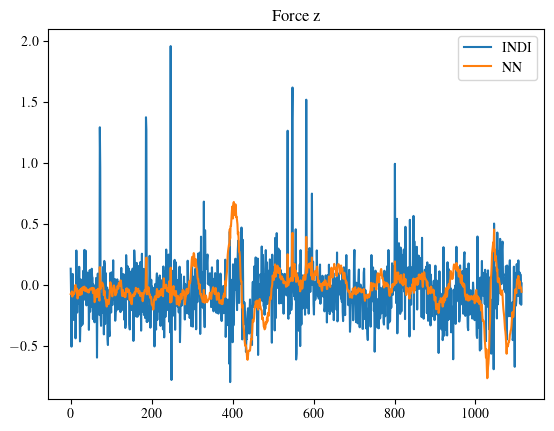

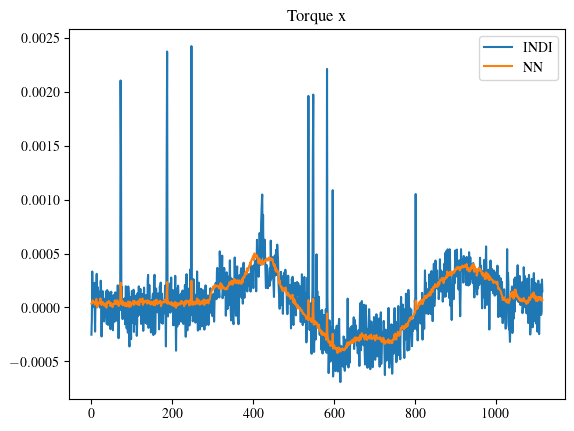

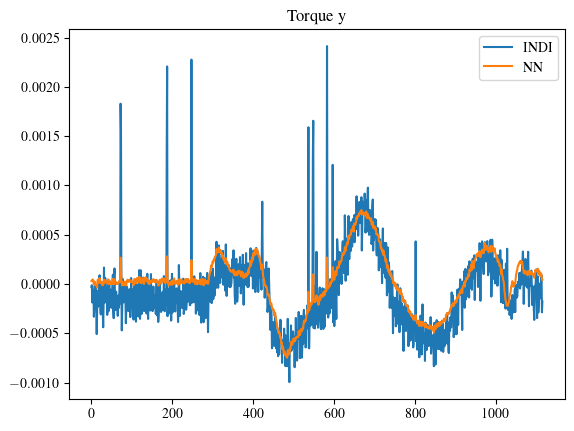

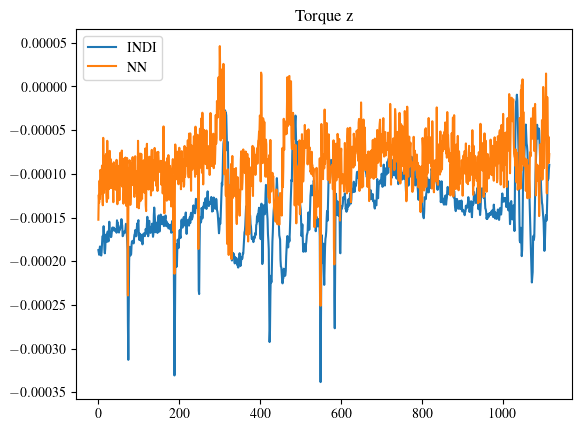

In [23]:
residual_func = lambda data: indi_residuals(data, make_smooth=False, verbose=0)

X_test, y_test = prepare_data([testing_data_paths[0]],
                               save_as="test_data",
                               shuffle_data=False,
                               residual_func=residual_func,
                               overwrite=True,
                               payload=True,
                               kappas=kappas,
                               verbose=1)

X_test, _, _ = min_max(X_test, X_mins, X_maxs)
y_test, _, _ = min_max(y_test, y_mins, y_maxs)

print(y_test.shape)

weights = torch.load('./models/mlp.pth')
model.load_state_dict(weights)
model.float()

tensor_input = torch.from_numpy(X_test).type(torch.float32)
pred = model.forward(tensor_input).detach().numpy()
error = np.abs(y_test-pred)
print(f"Average force error: (x, y, z) N -> ({np.mean(error[:, 0]):.4f}, {np.mean(error[:, 1]):.4f}, {np.mean(error[:, 2]):.4f}) N")
print(f"Average torque error: (x, y, z) N -> ({np.mean(error[:, 3]):.4f}, {np.mean(error[:, 4]):.4f}, {np.mean(error[:, 5]):.4f}) N")

y_test_scaled = (y_test + 1) * .5 * (y_maxs - y_mins) + y_mins
pred_scaled = (pred + 1) * .5 * (y_maxs - y_mins) + y_mins

dims = ['x', 'y', 'z']
force_type = ["Force", "Torque"]
for i in range(6):
    fig, ax = plt.subplots()
    ax.set_title(f"{force_type[i//3]} {dims[i%3]}")
    ax.plot(y_test_scaled[:, i], label="INDI")
    ax.plot(pred_scaled[:, i], label="NN")
    ax.legend()
    
    # axins = zoomed_inset_axes(ax, 3, loc=3)
    # axins.plot(y_test_scaled[:, i])
    # axins.plot(pred_scaled[:, i])

    # x1, x2, y1, y2 = 200, 240, .027, .037
    # axins.set_xlim(x1, x2)
    # axins.set_ylim(y1, y2)

    # plt.xticks(visible=False)
    # plt.yticks(visible=False)
    # mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.5")

    plt.draw()
    plt.show()

## Translating the model to c code

Comparing with original...
Models give the same outputs!


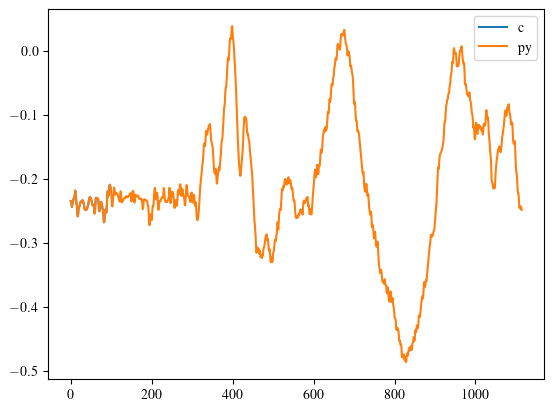

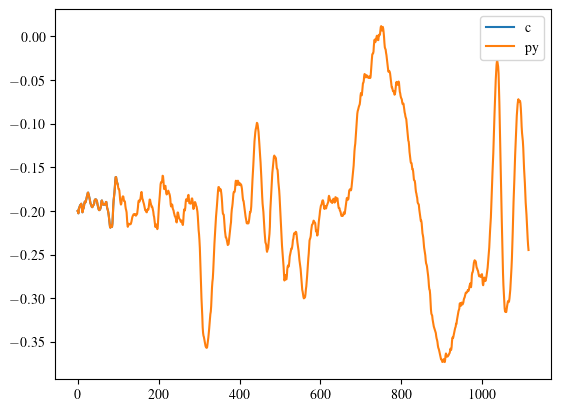

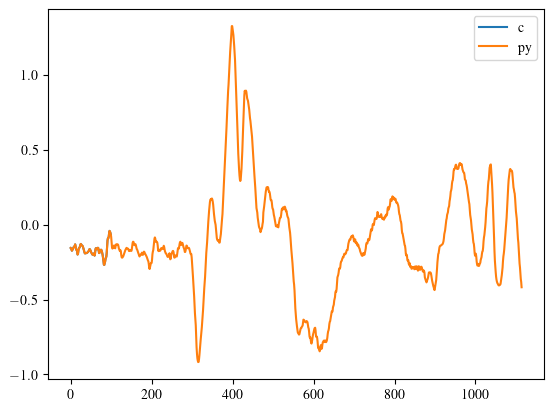

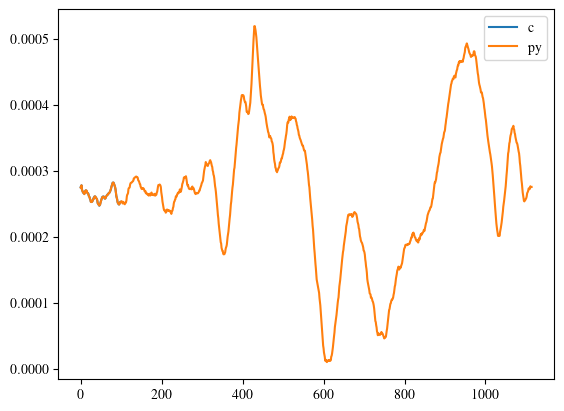

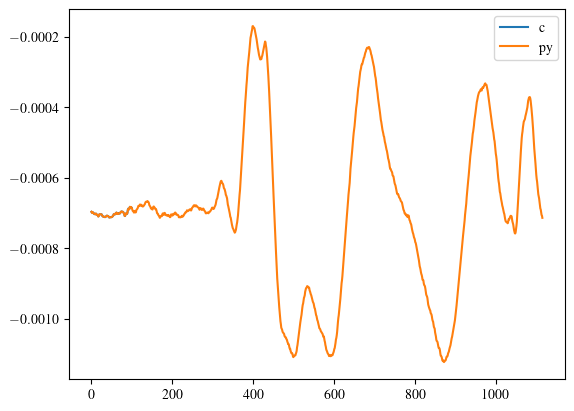

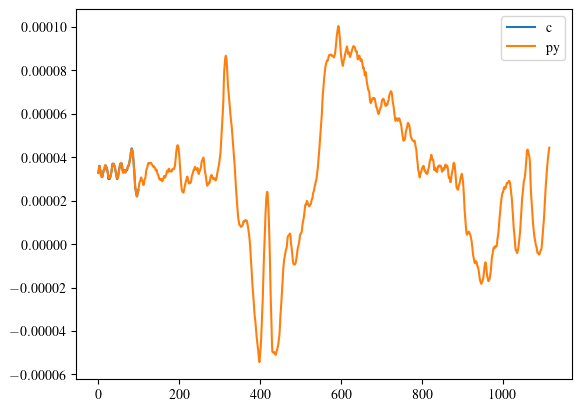

In [24]:
# Generate the model c code
model_path = "./models/mlp.pth"
exportNet(model_path, X_mins=X_mins, X_maxs=X_maxs, y_mins=y_mins, y_maxs=y_maxs, info="Neural network for the 2.1 Crazyflie", resnet_arch=True)

# Test if the generated model gives the same outputs as the original
model.double()
passed = nn_c_model_test(model, X_mins=X_mins, X_maxs=X_maxs, y_mins=y_mins, y_maxs=y_maxs, in_dim=X_train.shape[1], test_data=X_test, verbose=1)

## Adding the model to the cf-firmware

In [25]:
if passed:
    try:
        shutil.copyfile("./LMCE/c_utils/nn.c", "../crazyflie-firmware/src/modules/src/controller/nn.c")
        shutil.copyfile("./LMCE/c_utils/nn.h", "../crazyflie-firmware/src/modules/interface/controller/nn.h")
        print("Successfully copied nn to firmware.")
    except:
        print("Crazyflie firmware not found.")

Successfully copied nn to firmware.
